Name: Ivy Cheng

Github Username: ivychengusc

USC ID: 6931463618

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE, RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from matplotlib.lines import Line2D
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

## 1(a)

In [2]:
data_path = '../data/AReM'

activities = [
    'bending1',
    'bending2',
    'cycling',
    'lying',
    'sitting',
    'standing',
    'walking'
]

for activity in activities:
    folder_path = os.path.join(data_path, activity)
    print(activity, len([
        file for file in os.listdir(folder_path)
        if file.endswith('.csv')
    ]))

bending1 7
bending2 6
cycling 15
lying 15
sitting 15
standing 15
walking 15


## 1(b)

In [3]:
train_files = []
test_files = []

for activity in activities:
    
    folder_path = os.path.join(
        data_path,
        activity
    )
    
    files = [
        file for file in os.listdir(folder_path)
        if file.startswith('dataset')
        and file.endswith('.csv')
    ]
    
    files = sorted(
        files,
        key=lambda x: int(
            x.replace('dataset', '')
             .replace('.csv', '')
        )
    )
    
    for file in files:
        
        dataset_number = int(
            file.replace('dataset', '')
                .replace('.csv', '')
        )
        
        file_path = os.path.join(
            folder_path,
            file
        )
        
        if activity in ['bending1', 'bending2']:
            
            if dataset_number <= 2:
                test_files.append(
                    (activity, file_path)
                )
            else:
                train_files.append(
                    (activity, file_path)
                )
        
        else:
            
            if dataset_number <= 3:
                test_files.append(
                    (activity, file_path)
                )
            else:
                train_files.append(
                    (activity, file_path)
                )

print("Training instances:", len(train_files))
print("Test instances:", len(test_files))

Training instances: 69
Test instances: 19


## 1(c)(i)
Commonly used time-domain features for time series classification include minimum, maximum, mean, median, standard deviation, variance, range, first quartile, third quartile, interquartile range, root mean square, skewness, kurtosis, zero-crossing rate, autocorrelation.

## 1(c)(ii)

In [4]:
time_series_names = [
    'avg_rss12',
    'var_rss12',
    'avg_rss13',
    'var_rss13',
    'avg_rss23',
    'var_rss23'
]

In [5]:
def read_activity_file(file_path):
    
    with open(file_path, 'r') as file:
        
        for line in file:
            
            if (
                line.strip()
                and not line.startswith('#')
            ):
                
                if ',' in line:
                    separator = ','
                else:
                    separator = r'\s+'
                
                break
    
    data = pd.read_csv(
        file_path,
        comment='#',
        header=None,
        sep=separator,
        usecols=range(7),
        engine='python'
    )
    
    data.columns = [
        'time',
        'avg_rss12',
        'var_rss12',
        'avg_rss13',
        'var_rss13',
        'avg_rss23',
        'var_rss23'
    ]
    
    return data

In [6]:
all_files = []

for activity in activities:
    
    folder_path = os.path.join(
        data_path,
        activity
    )
    
    files = [
        file for file in os.listdir(folder_path)
        if file.startswith('dataset')
        and file.endswith('.csv')
    ]
    
    files = sorted(
        files,
        key=lambda x: int(
            x.replace('dataset', '')
             .replace('.csv', '')
        )
    )
    
    for file in files:
        
        all_files.append(
            os.path.join(
                folder_path,
                file
            )
        )

print("Number of instances:", len(all_files))

Number of instances: 88


In [7]:
feature_rows = []

for instance_number, file_path in enumerate(
    all_files,
    start=1
):
    
    data = read_activity_file(
        file_path
    )
    
    row = {
        'Instance': instance_number
    }
    
    for i, column in enumerate(
        time_series_names,
        start=1
    ):
        
        series = data[column]
        
        row['min' + str(i)] = (
            series.min()
        )
        
        row['max' + str(i)] = (
            series.max()
        )
        
        row['mean' + str(i)] = (
            series.mean()
        )
        
        row['median' + str(i)] = (
            series.median()
        )
        
        row['std' + str(i)] = (
            series.std()
        )
        
        row['1st_quart' + str(i)] = (
            series.quantile(0.25)
        )
        
        row['3rd_quart' + str(i)] = (
            series.quantile(0.75)
        )
    
    feature_rows.append(row)

In [8]:
feature_df = pd.DataFrame(
    feature_rows
)

feature_df.head()

,Instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [9]:
print(feature_df.shape)

(88, 43)


In [10]:
print(
    "Missing values:",
    feature_df.isna().sum().sum()
)

Missing values: 0


For each of the six time series in every instance, I extracted the following seven time-domain features: minimum, maximum, mean, median, standard deviation, first quartile, third quartile.

Therefore, each instance has

$$
6 \times 7 = 42
$$

time-domain features.

Since the dataset contains 88 instances, the resulting feature dataset contains 88 rows and 42 extracted features. An additional Instance column is included for identification, so the DataFrame has 43 columns in total.

## 1(c)(iii)

In [11]:
feature_columns = feature_df.columns.drop('Instance')

np.random.seed(42)

bootstrap_results = []

for feature in feature_columns:
    
    values = feature_df[feature].to_numpy()
    
    estimated_std = np.std(
        values,
        ddof=1
    )
    
    bootstrap_std = []
    
    for i in range(1000):
        
        bootstrap_sample = np.random.choice(
            values,
            size=len(values),
            replace=True
        )
        
        bootstrap_std.append(
            np.std(
                bootstrap_sample,
                ddof=1
            )
        )
    
    lower_bound = np.percentile(
        bootstrap_std,
        5
    )
    
    upper_bound = np.percentile(
        bootstrap_std,
        95
    )
    
    bootstrap_results.append([
        feature,
        estimated_std,
        lower_bound,
        upper_bound
    ])

In [12]:
std_ci_table = pd.DataFrame(
    bootstrap_results,
    columns=[
        'Feature',
        'Standard Deviation',
        '90% CI Lower',
        '90% CI Upper'
    ]
)

std_ci_table.round(3)

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.570,8.267,10.693
1,max1,4.394,3.370,5.293
2,mean1,5.336,4.720,5.902
3,median1,5.440,4.763,6.018
4,std1,1.772,1.571,1.953
5,1st_quart1,6.154,5.546,6.660
6,3rd_quart1,5.139,4.388,5.841
7,min2,0.000,0.000,0.000
8,max2,5.063,4.627,5.404
9,mean2,1.574,1.402,1.714


The table above shows the estimated standard deviation and the 90% bootstrap confidence interval for each of the 42 time-domain features.

The sample standard deviation is calculated across the 88 activity instances. For each feature, 1,000 bootstrap samples are generated by sampling the 88 observations with replacement.

A 90% percentile bootstrap confidence interval is obtained using the 5th and 95th percentiles of the bootstrap standard deviations.

## 1(c)(iv)
I would select mean, standard deviation, and maximum as the three most important time-domain features.

Mean represents the overall level of a time series and can help distinguish activities that produce different average sensor measurements. Standard deviation measures the amount of variation in a time series. Activities involving more movement are likely to have greater variability than relatively stationary activities. Maximum captures the peak value of a time series and may help identify activities that produce large or sudden sensor readings.

Together, these three features describe the central tendency, variability, and extreme behavior of each time series, which makes them useful for distinguishing different types of activities.

## 2(a)(i)

In [13]:
binary_train_rows = []

for activity, file_path in train_files:
    
    data = read_activity_file(file_path)
    
    row = {
        'mean1': data['avg_rss12'].mean(),
        'std1': data['avg_rss12'].std(),
        'max1': data['avg_rss12'].max(),
        
        'mean2': data['var_rss12'].mean(),
        'std2': data['var_rss12'].std(),
        'max2': data['var_rss12'].max(),
        
        'mean6': data['var_rss23'].mean(),
        'std6': data['var_rss23'].std(),
        'max6': data['var_rss23'].max(),
        
        'Class': 'Bending'
        if activity in ['bending1', 'bending2']
        else 'Other'
    }
    
    binary_train_rows.append(row)

binary_train_df = pd.DataFrame(binary_train_rows)

binary_train_df.head()

,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6,Class
0,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79,Bending
1,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18,Bending
2,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79,Bending
3,43.454958,1.386098,48.00,0.378083,0.315566,1.58,0.679646,0.622534,5.26,Bending
4,43.969125,1.618364,48.00,0.413125,0.263111,1.50,0.555312,0.487826,2.96,Bending


In [14]:
binary_train_df['Class'].value_counts()

Other      60
Bending     9
Name: Class, dtype: int64

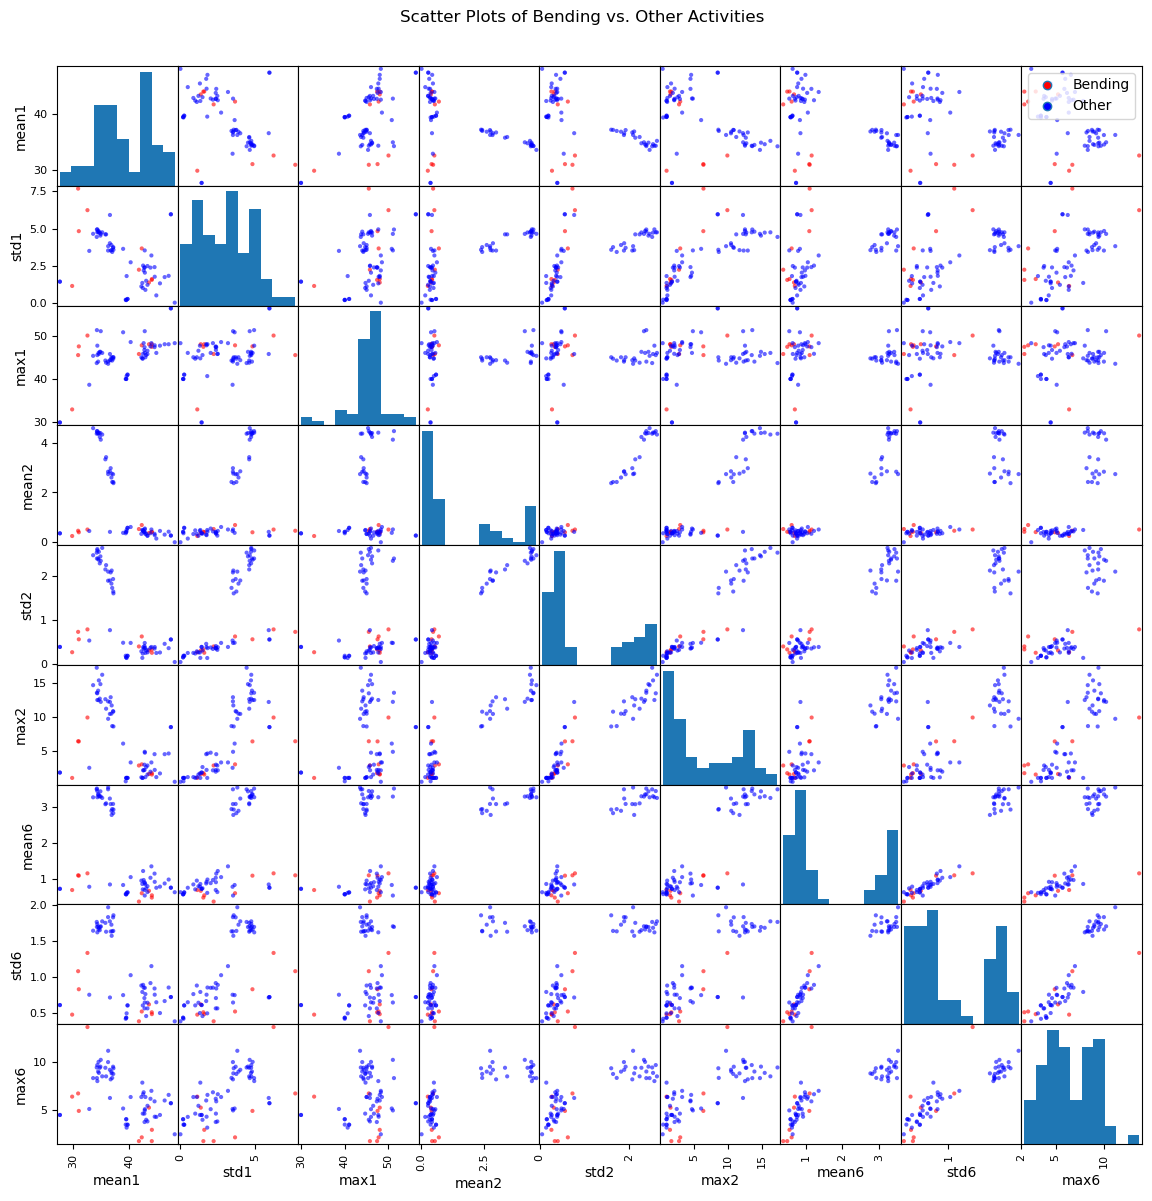

In [15]:
from matplotlib.lines import Line2D

plot_features = [
    'mean1', 'std1', 'max1',
    'mean2', 'std2', 'max2',
    'mean6', 'std6', 'max6'
]

colors = binary_train_df['Class'].map({
    'Bending': 'red',
    'Other': 'blue'
})

axes = pd.plotting.scatter_matrix(
    binary_train_df[plot_features],
    figsize=(14, 14),
    diagonal='hist',
    c=colors,
    alpha=0.6
)

legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        label='Bending',
        markerfacecolor='red'
    ),
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        label='Other',
        markerfacecolor='blue'
    )
]

axes[0, -1].legend(
    handles=legend_elements,
    loc='upper right'
)

plt.suptitle(
    'Scatter Plots of Bending vs. Other Activities',
    y=0.92
)

plt.show()

## 2(a)(ii)

In [16]:
split_train_rows = []

for activity, file_path in train_files:
    
    data = read_activity_file(file_path)
    
    midpoint = len(data) // 2
    
    first_half = data.iloc[:midpoint]
    second_half = data.iloc[midpoint:]
    
    row = {}
    
    selected_series = {
        1: 'avg_rss12',
        2: 'var_rss12',
        6: 'var_rss23'
    }
    
    for number, column in selected_series.items():
        
        row['mean' + str(number) + '_part1'] = first_half[column].mean()
        row['std' + str(number) + '_part1'] = first_half[column].std()
        row['max' + str(number) + '_part1'] = first_half[column].max()
        
        row['mean' + str(number) + '_part2'] = second_half[column].mean()
        row['std' + str(number) + '_part2'] = second_half[column].std()
        row['max' + str(number) + '_part2'] = second_half[column].max()
    
    if activity in ['bending1', 'bending2']:
        row['Class'] = 'Bending'
    else:
        row['Class'] = 'Other'
    
    split_train_rows.append(row)

split_train_df = pd.DataFrame(split_train_rows)

split_train_df.head()

,mean1_part1,std1_part1,max1_part1,mean1_part2,std1_part2,max1_part2,mean2_part1,std2_part1,max2_part1,mean2_part2,std2_part2,max2_part2,mean6_part1,std6_part1,max6_part1,mean6_part2,std6_part2,max6_part2,Class
0,44.057167,1.556971,46.50,43.851833,1.557168,47.40,0.381042,0.329540,1.50,0.471458,0.342346,1.70,0.598250,0.526656,1.79,0.388333,0.478528,1.50,Bending
1,43.278875,3.473355,47.75,41.080750,3.537481,46.00,0.673292,0.634285,3.00,0.718792,0.627915,2.86,0.640958,0.554542,1.53,0.586083,0.491873,2.18,Bending
2,41.621208,3.118644,45.75,41.734917,0.595920,43.67,0.623083,0.489595,2.83,0.448875,0.273050,1.12,0.419083,0.411200,1.79,0.347500,0.363144,1.50,Bending
3,44.117042,1.359836,48.00,42.792875,1.058792,46.50,0.250042,0.314099,1.30,0.506125,0.260761,1.58,0.815417,0.718016,5.26,0.543875,0.473445,4.06,Bending
4,43.486208,1.281976,45.00,44.452042,1.771251,48.00,0.378667,0.284434,1.30,0.447583,0.235493,1.50,0.524875,0.486847,2.28,0.585750,0.487918,2.96,Bending


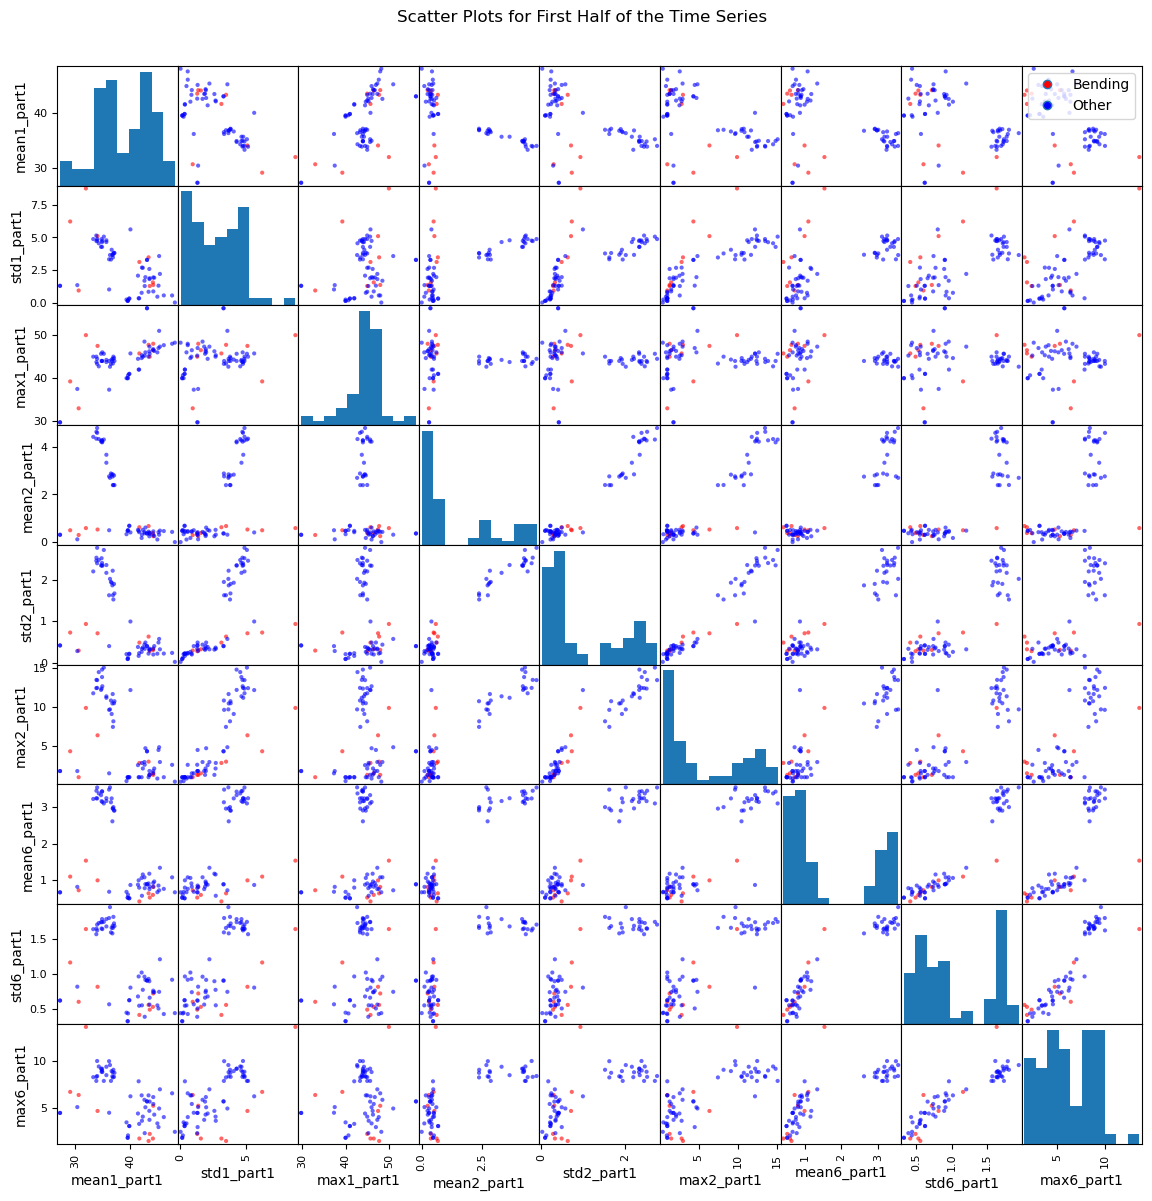

In [17]:
part1_features = [
    'mean1_part1', 'std1_part1', 'max1_part1',
    'mean2_part1', 'std2_part1', 'max2_part1',
    'mean6_part1', 'std6_part1', 'max6_part1'
]

colors = split_train_df['Class'].map({
    'Bending': 'red',
    'Other': 'blue'
})

axes = pd.plotting.scatter_matrix(
    split_train_df[part1_features],
    figsize=(14, 14),
    diagonal='hist',
    c=colors,
    alpha=0.6
)

axes[0, -1].legend(
    handles=legend_elements,
    loc='upper right'
)

plt.suptitle(
    'Scatter Plots for First Half of the Time Series',
    y=0.92
)

plt.show()

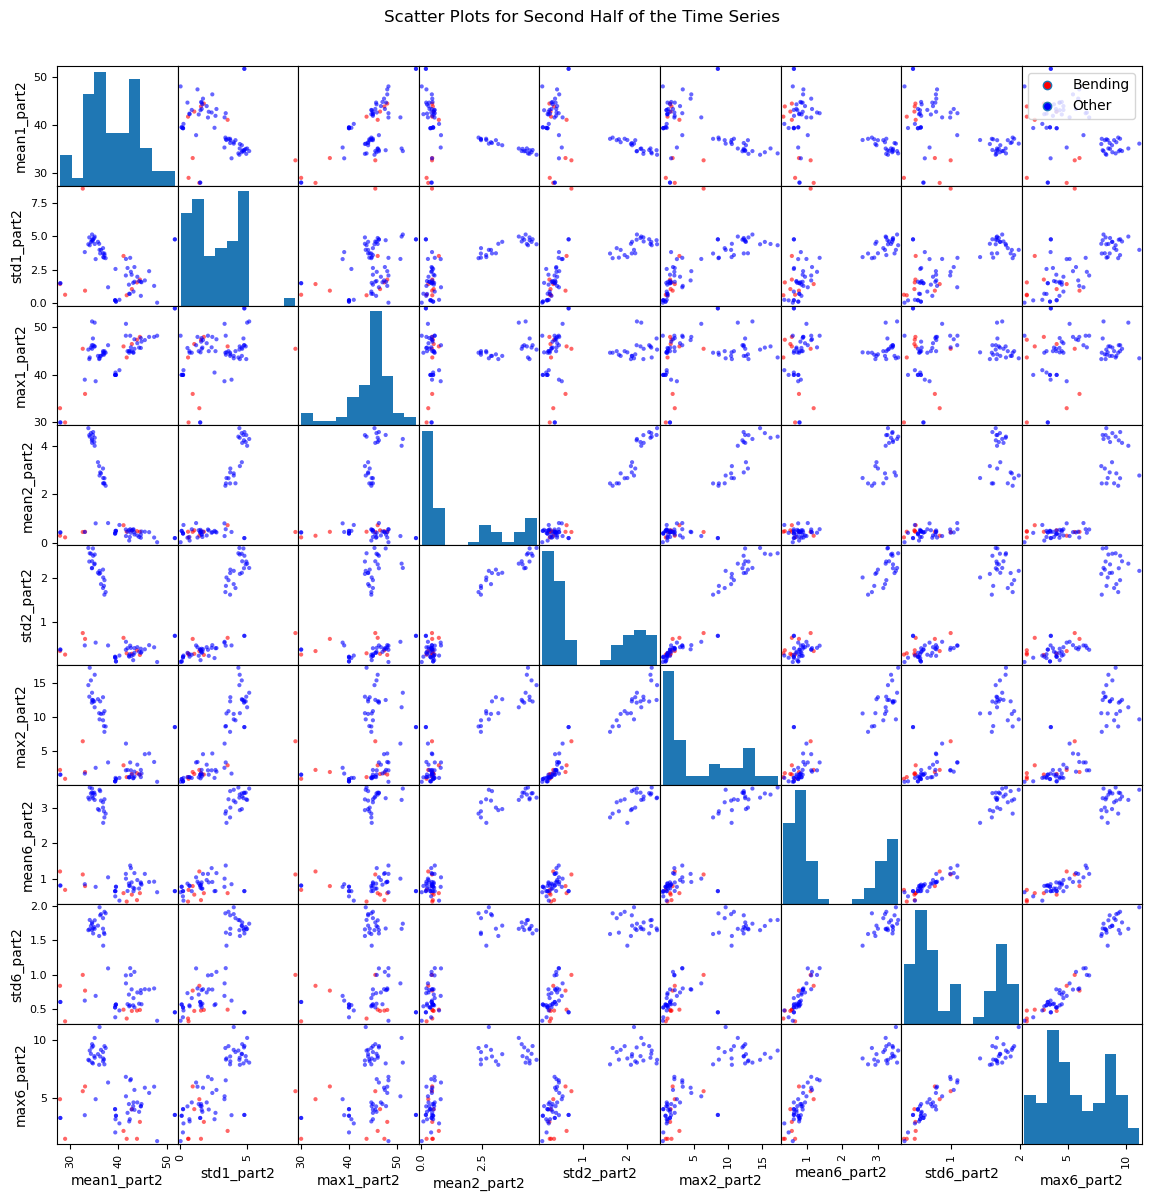

In [18]:
part2_features = [
    'mean1_part2', 'std1_part2', 'max1_part2',
    'mean2_part2', 'std2_part2', 'max2_part2',
    'mean6_part2', 'std6_part2', 'max6_part2'
]

axes = pd.plotting.scatter_matrix(
    split_train_df[part2_features],
    figsize=(14, 14),
    diagonal='hist',
    c=colors,
    alpha=0.6
)

axes[0, -1].legend(
    handles=legend_elements,
    loc='upper right'
)

plt.suptitle(
    'Scatter Plots for Second Half of the Time Series',
    y=0.92
)

plt.show()

There is no considerable difference compared with the scatter plots in 2(a)(i). After splitting each time series into two parts, some feature combinations show slightly clearer separation between bending and the other activities, but overall pattern remains similar and there is still some overlap between the two classes.

## 2(a)(iii)

In [19]:
def make_binary_features(file_list, l):
    
    feature_rows = []
    labels = []
    
    for activity, file_path in file_list:
        
        data = read_activity_file(file_path)
        row = {}
        
        for series_number, column in enumerate(
            time_series_names,
            start=1
        ):
            
            parts = np.array_split(
                data[column].to_numpy(),
                l
            )
            
            for part_number, part in enumerate(
                parts,
                start=1
            ):
                
                row[
                    'mean' +
                    str(series_number) +
                    '_' +
                    str(part_number)
                ] = np.mean(part)
                
                row[
                    'std' +
                    str(series_number) +
                    '_' +
                    str(part_number)
                ] = np.std(
                    part,
                    ddof=1
                )
                
                row[
                    'max' +
                    str(series_number) +
                    '_' +
                    str(part_number)
                ] = np.max(part)
        
        feature_rows.append(row)
        
        if activity in ['bending1', 'bending2']:
            labels.append(1)
        else:
            labels.append(0)
    
    X = pd.DataFrame(feature_rows)
    y = np.array(labels)
    
    return X, y

For each value of $l$, each of the 6 original time series is divided into $l$ parts. Three features are extracted from each part: mean, standard deviation, and maximum.

Therefore, the number of features before feature selection is

$$
6 \times l \times 3 = 18l.
$$

In [20]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []
rfecv_models = {}

for l in range(1, 21):
    
    X, y = make_binary_features(
        train_files,
        l
    )
    
    model = LogisticRegression(
        C=1000000,
        solver='liblinear',
        max_iter=1000
    )
    
    selector = RFECV(
        estimator=model,
        step=1,
        cv=cv,
        scoring='accuracy',
        min_features_to_select=1,
        n_jobs=-1
    )
    
    selector.fit(X, y)
    
    best_accuracy = selector.cv_results_[
        'mean_test_score'
    ].max()
    
    cv_results.append({
        'l': l,
        'p': selector.n_features_,
        'CV Accuracy': best_accuracy
    })
    
    rfecv_models[l] = (
        selector,
        X.columns
    )

In [21]:
cv_results_df = pd.DataFrame(
    cv_results
)

cv_results_df

,l,p,CV Accuracy
0,1,9,0.956044
1,2,10,0.956044
2,3,5,0.971429
3,4,13,0.971429
4,5,10,0.985714
5,6,9,0.971429
6,7,19,0.985714
7,8,9,0.971429
8,9,3,0.971429
9,10,22,0.957143


In [22]:
best_row = cv_results_df.loc[
    cv_results_df['CV Accuracy'].idxmax()
]

best_l = int(
    best_row['l']
)

best_p = int(
    best_row['p']
)

best_cv_accuracy = best_row[
    'CV Accuracy'
]

print(
    "Best l:",
    best_l
)

print(
    "Best p:",
    best_p
)

print(
    "Best CV accuracy:",
    round(best_cv_accuracy, 4)
)

Best l: 5
Best p: 10
Best CV accuracy: 0.9857


In [23]:
best_selector, best_columns = (
    rfecv_models[best_l]
)

selected_features = best_columns[
    best_selector.support_
].tolist()

print(
    "Selected features:"
)

for feature in selected_features:
    print(feature)

Selected features:
max1_3
mean1_4
max2_2
mean3_1
mean5_1
max5_1
mean5_2
mean5_5
max6_2
max6_3


The best model from 5-fold cross-validation uses $l=5$ and $p=10$, with a cross-validation accuracy of 0.9857.

The wrong way to do cross-validation in this problem would be to select the features using the entire training set first and then run cross-validation. This would allow information from the validation folds to affect the feature selection step, so the cross-validation accuracy could be too optimistic.

The correct way is to perform feature selection inside each training fold and evaluate the selected model only on the corresponding validation fold. I used RFECV so that recursive feature elimination is performed as part of the cross-validation process.

I also used stratified 5-fold cross-validation because the bending class has fewer observations than the other class. Stratification helps keep a similar class distribution in each fold.

## 2(a)(iv)

In [24]:
X_train_all, y_train = make_binary_features(
    train_files,
    best_l
)

X_train = X_train_all[
    selected_features
]

final_model = LogisticRegression(
    C=1000000,
    solver='liblinear',
    max_iter=1000
)

final_model.fit(
    X_train,
    y_train
)

y_train_pred = final_model.predict(
    X_train
)

y_train_prob = final_model.predict_proba(
    X_train
)[:, 1]

In [25]:
train_cm = confusion_matrix(
    y_train,
    y_train_pred
)

train_cm_df = pd.DataFrame(
    train_cm,
    index=[
        'Actual Other',
        'Actual Bending'
    ],
    columns=[
        'Predicted Other',
        'Predicted Bending'
    ]
)

train_cm_df

,Predicted Other,Predicted Bending
Actual Other,60,0
Actual Bending,0,9


In [26]:
train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

print(
    "Training accuracy:",
    round(train_accuracy, 4)
)

Training accuracy: 1.0


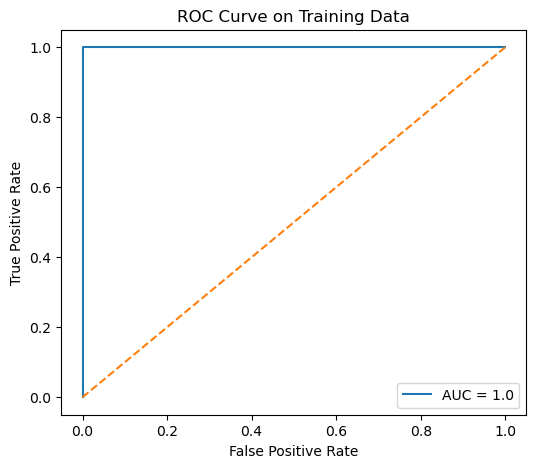

Training AUC: 1.0


In [27]:
fpr, tpr, thresholds = roc_curve(
    y_train,
    y_train_prob
)

train_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label='AUC = ' + str(round(train_auc, 4))
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve on Training Data')
plt.legend()

plt.show()

print(
    "Training AUC:",
    round(train_auc, 4)
)

In [28]:
X_train_sm = sm.add_constant(
    X_train
)

logit_model = sm.Logit(
    y_train,
    X_train_sm
)

logit_result = logit_model.fit(
    maxiter=20,
    disp=False
)

/opt/anaconda3/envs/GenZest/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [29]:
parameter_table = pd.DataFrame({
    'Coefficient': logit_result.params,
    'P-value': logit_result.pvalues
})

parameter_table

,Coefficient,P-value
const,-33.420701,0.999657
max1_3,0.498842,0.999846
mean1_4,-2.023730,0.999247
max2_2,-0.753400,0.999475
mean3_1,-1.446460,0.999137
mean5_1,3.485793,0.999588
max5_1,1.501776,0.999458
mean5_2,-0.573646,0.999950
mean5_5,1.194401,0.999614
max6_2,-1.049750,0.999837


The confusion matrix, ROC curve, and AUC above show the performance of the logistic regression model on the training data. The table reports the estimated coefficients and their corresponding p-values.

The logistic regression model did not fully converge because the two classes are nearly perfectly separated. Therefore, the coefficient and p-value estimates may be unstable. I limited the maximum number of iterations to reduce the instability caused by perfect separation.

## 2(a)(v)

In [30]:
X_test_all, y_test = make_binary_features(
    test_files,
    best_l
)

X_test = X_test_all[
    selected_features
]

y_test_pred = final_model.predict(
    X_test
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

print(
    "Test accuracy:",
    round(test_accuracy, 4)
)

print(
    "Cross-validation accuracy:",
    round(best_cv_accuracy, 4)
)

Test accuracy: 1.0
Cross-validation accuracy: 0.9857


In [31]:
print(
    "Test set shape:",
    X_test.shape
)

Test set shape: (19, 10)


The test accuracy is 1.0000, while the 5-fold cross-validation accuracy is 0.9857. The test accuracy is slightly higher than the cross-validation accuracy, and both results indicate that the classifier performs very well on this binary classification problem.

## 2(a)(vi)

Yes. The classes appear to be well separated, which causes instability when estimating the logistic regression parameters.

When I fit the logistic regression model using statsmodels, I received a perfect separation warning and the model also failed to fully converge. This suggests that the selected features can almost completely separate bending from the other activities, so the coefficient estimates can become very large or unstable.

## 2(a)(vii)

In [32]:
print(
    "Other:",
    np.sum(y_train == 0)
)

print(
    "Bending:",
    np.sum(y_train == 1)
)

Other: 60
Bending: 9


In [33]:
np.random.seed(42)

other_index = np.where(
    y_train == 0
)[0]

bending_index = np.where(
    y_train == 1
)[0]

sampled_bending_index = np.random.choice(
    bending_index,
    size=len(other_index),
    replace=True
)

case_control_index = np.concatenate([
    other_index,
    sampled_bending_index
])

X_case_control = X_train.iloc[
    case_control_index
]

y_case_control = y_train[
    case_control_index
]

print(
    "Other:",
    np.sum(y_case_control == 0)
)

print(
    "Bending:",
    np.sum(y_case_control == 1)
)

Other: 60
Bending: 60


In [34]:
case_control_model = LogisticRegression(
    C=1000000,
    solver='liblinear',
    max_iter=1000
)

case_control_model.fit(
    X_case_control,
    y_case_control
)

LogisticRegression(C=1000000, max_iter=1000, solver='liblinear')

In [35]:
original_p = y_train.mean()
case_control_p = y_case_control.mean()

intercept_adjustment = (
    np.log(
        original_p /
        (1 - original_p)
    )
    -
    np.log(
        case_control_p /
        (1 - case_control_p)
    )
)

adjusted_intercept = (
    case_control_model.intercept_[0]
    +
    intercept_adjustment
)

print(
    "Original case-control intercept:",
    case_control_model.intercept_[0]
)

print(
    "Intercept adjustment:",
    intercept_adjustment
)

print(
    "Adjusted intercept:",
    adjusted_intercept
)

Original case-control intercept: -0.034600205210137056
Intercept adjustment: -1.8971199848858813
Adjusted intercept: -1.9317201900960184


In [36]:
linear_score = (
    X_train.to_numpy()
    @ case_control_model.coef_[0]
    +
    adjusted_intercept
)

case_control_prob = 1 / (
    1 + np.exp(-linear_score)
)

case_control_pred = (
    case_control_prob >= 0.5
).astype(int)

In [37]:
case_control_cm = confusion_matrix(
    y_train,
    case_control_pred
)

case_control_cm_df = pd.DataFrame(
    case_control_cm,
    index=[
        'Actual Other',
        'Actual Bending'
    ],
    columns=[
        'Predicted Other',
        'Predicted Bending'
    ]
)

case_control_cm_df

,Predicted Other,Predicted Bending
Actual Other,60,0
Actual Bending,0,9


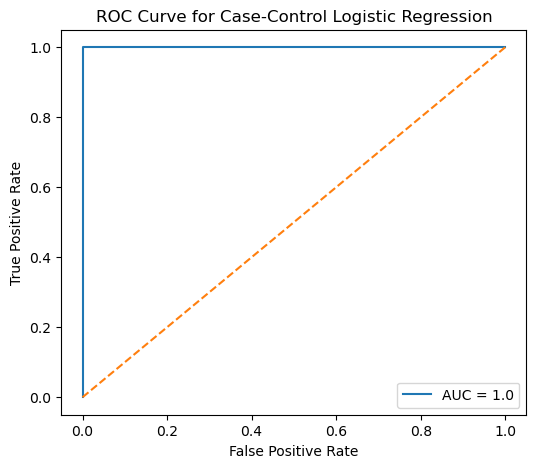

AUC: 1.0


In [38]:
cc_fpr, cc_tpr, thresholds = roc_curve(
    y_train,
    case_control_prob
)

cc_auc = auc(
    cc_fpr,
    cc_tpr
)

plt.figure(figsize=(6, 5))

plt.plot(
    cc_fpr,
    cc_tpr,
    label='AUC = ' + str(round(cc_auc, 4))
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Case-Control Logistic Regression')
plt.legend()

plt.show()

print(
    "AUC:",
    round(cc_auc, 4)
)

The training data are imbalanced, with 60 observations from the Other class and 9 observations from the Bending class.

I used case-control sampling to balance the two classes and adjusted the intercept of the logistic regression model to account for the change in class proportions.

The confusion matrix shows that all 69 training observations are classified correctly, with no false positives or false negatives. The AUC is 1.0, which indicates perfect separation between the two classes on the training data.

## 2(b)(i)

In [39]:
l1_results = []

C_values = np.logspace(
    -3,
    3,
    20
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for l in range(1, 21):
    
    X, y = make_binary_features(
        train_files,
        l
    )
    
    pipeline = Pipeline([
        (
            'scaler',
            StandardScaler()
        ),
        (
            'model',
            LogisticRegression(
                penalty='l1',
                solver='liblinear',
                max_iter=1000
            )
        )
    ])
    
    grid = GridSearchCV(
        pipeline,
        param_grid={
            'model__C': C_values
        },
        cv=cv,
        scoring='accuracy'
    )
    
    grid.fit(
        X,
        y
    )
    
    l1_results.append({
        'l': l,
        'C': grid.best_params_[
            'model__C'
        ],
        'CV Accuracy': grid.best_score_
    })

In [40]:
l1_results_df = pd.DataFrame(
    l1_results
)

l1_results_df

,l,C,CV Accuracy
0,1,2.976351,0.971429
1,2,2.976351,0.942857
2,3,0.335982,0.971429
3,4,0.695193,0.971429
4,5,0.695193,0.941758
5,6,0.335982,0.957143
6,7,0.335982,0.941758
7,8,1000.000000,0.942857
8,9,0.162378,0.913187
9,10,1.438450,0.957143


In [41]:
best_l1_row = l1_results_df.loc[
    l1_results_df[
        'CV Accuracy'
    ].idxmax()
]

best_l_l1 = int(
    best_l1_row['l']
)

best_C_l1 = best_l1_row['C']

best_l1_cv_accuracy = best_l1_row[
    'CV Accuracy'
]

best_lambda_l1 = 1 / best_C_l1

print(
    "Best l:",
    best_l_l1
)

print(
    "Best C:",
    best_C_l1
)

print(
    "Best lambda:",
    best_lambda_l1
)

print(
    "Best CV accuracy:",
    round(
        best_l1_cv_accuracy,
        4
    )
)

Best l: 12
Best C: 0.6951927961775606
Best lambda: 1.4384498882876628
Best CV accuracy: 0.9857


In [42]:
X_l1, y_l1 = make_binary_features(
    train_files,
    best_l_l1
)

l1_model = Pipeline([
    (
        'scaler',
        StandardScaler()
    ),
    (
        'model',
        LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=best_C_l1,
            max_iter=1000
        )
    )
])

l1_model.fit(
    X_l1,
    y_l1
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=0.6951927961775606, max_iter=1000,
                                    penalty='l1', solver='liblinear'))])

In [43]:
l1_coefficients = l1_model[
    'model'
].coef_[0]

l1_selected_features = X_l1.columns[
    l1_coefficients != 0
].tolist()

print(
    "Number of selected features:",
    len(l1_selected_features)
)

print(
    "Selected features:"
)

for feature in l1_selected_features:
    print(feature)

Number of selected features: 5
Selected features:
max1_7
std3_3
mean5_2
mean5_11
max6_11


Using 5-fold stratified cross-validation, the best L1-penalized logistic regression model was obtained with

$$
l = 12
$$

and

$$
C = 0.6952.
$$

Since $\lambda = 1/C$, the corresponding penalty parameter is

$$
\lambda \approx 1.4384.
$$

The best cross-validation accuracy is 0.9857.

The L1 penalty selected 5 features with non-zero coefficients:

- max1_7
- std3_3
- mean5_2
- mean5_11
- max6_11

## 2(b)(ii)

The L1-penalized logistic regression and the variable-selection approach in 2(a)(iii) have the same best cross-validation accuracy of 0.9857.

For the variable-selection model, the best result was obtained with $l=5$ and $p=10$. The L1-penalized model used $l=12$ and selected only 5 features with non-zero coefficients.

Based on cross-validation accuracy, neither method performs better because they achieve the same accuracy. However, the L1-penalized logistic regression produces a smaller set of selected features.

The L1 method is also easier to implement because feature selection is performed automatically through the L1 penalty. In comparison, the variable-selection approach requires an additional feature-selection step.

## 2(c)(i)

In [44]:
def make_multiclass_features(file_list, l):
    
    feature_rows = []
    labels = []
    
    for activity, file_path in file_list:
        
        data = read_activity_file(file_path)
        row = {}
        
        for series_number, column in enumerate(
            time_series_names,
            start=1
        ):
            
            parts = np.array_split(
                data[column].to_numpy(),
                l
            )
            
            for part_number, part in enumerate(
                parts,
                start=1
            ):
                
                row[
                    'mean' +
                    str(series_number) +
                    '_' +
                    str(part_number)
                ] = np.mean(part)
                
                row[
                    'std' +
                    str(series_number) +
                    '_' +
                    str(part_number)
                ] = np.std(
                    part,
                    ddof=1
                )
                
                row[
                    'max' +
                    str(series_number) +
                    '_' +
                    str(part_number)
                ] = np.max(part)
        
        feature_rows.append(row)
        labels.append(activity)
    
    X = pd.DataFrame(feature_rows)
    y = np.array(labels)
    
    return X, y

In [45]:
multiclass_results = []

C_values = np.logspace(
    -3,
    2,
    15
)

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

for l in range(1, 21):
    
    X, y = make_multiclass_features(
        train_files,
        l
    )
    
    pipeline = Pipeline([
        (
            'scaler',
            StandardScaler()
        ),
        (
            'model',
            LogisticRegression(
                penalty='l1',
                solver='saga',
                max_iter=20000,
                random_state=42
            )
        )
    ])
    
    grid = GridSearchCV(
        pipeline,
        param_grid={
            'model__C': C_values
        },
        cv=cv_multi,
        scoring='accuracy',
        n_jobs=-1
    )
    
    grid.fit(
        X,
        y
    )
    
    multiclass_results.append({
        'l': l,
        'C': grid.best_params_['model__C'],
        'CV Accuracy': grid.best_score_
    })

In [46]:
multiclass_results_df = pd.DataFrame(
    multiclass_results
)

multiclass_results_df

,l,C,CV Accuracy
0,1,43.939706,0.898693
1,2,43.939706,0.839869
2,3,8.483429,0.839869
3,4,8.483429,0.869281
4,5,43.939706,0.883170
5,6,43.939706,0.854575
6,7,1.637894,0.839869
7,8,43.939706,0.825980
8,9,100.000000,0.883987
9,10,100.000000,0.854575


In [47]:
best_multi_row = multiclass_results_df.loc[
    multiclass_results_df[
        'CV Accuracy'
    ].idxmax()
]

best_multi_l = int(
    best_multi_row['l']
)

best_multi_C = best_multi_row['C']

best_multi_cv_accuracy = best_multi_row[
    'CV Accuracy'
]

print(
    "Best l:",
    best_multi_l
)

print(
    "Best C:",
    best_multi_C
)

print(
    "Best CV accuracy:",
    round(
        best_multi_cv_accuracy,
        4
    )
)

Best l: 1
Best C: 43.93970560760795
Best CV accuracy: 0.8987


In [48]:
X_train_multi, y_train_multi = (
    make_multiclass_features(
        train_files,
        best_multi_l
    )
)

multi_model = Pipeline([
    (
        'scaler',
        StandardScaler()
    ),
    (
        'model',
        LogisticRegression(
            penalty='l1',
            solver='saga',
            C=best_multi_C,
            max_iter=5000,
            random_state=42
        )
    )
])

multi_model.fit(
    X_train_multi,
    y_train_multi
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=43.93970560760795, max_iter=5000,
                                    penalty='l1', random_state=42,
                                    solver='saga'))])

In [49]:
X_test_multi, y_test_multi = (
    make_multiclass_features(
        test_files,
        best_multi_l
    )
)

y_test_multi_pred = multi_model.predict(
    X_test_multi
)

test_accuracy_multi = accuracy_score(
    y_test_multi,
    y_test_multi_pred
)

test_error_multi = (
    1 - test_accuracy_multi
)

print(
    "Test accuracy:",
    round(
        test_accuracy_multi,
        4
    )
)

print(
    "Test error:",
    round(
        test_error_multi,
        4
    )
)

Test accuracy: 0.8947
Test error: 0.1053


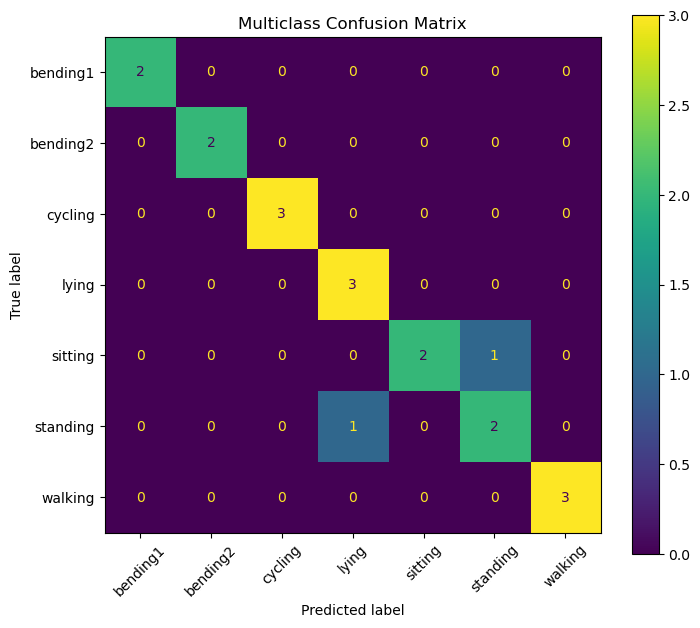

In [50]:
class_names = multi_model[
    'model'
].classes_

multi_cm = confusion_matrix(
    y_test_multi,
    y_test_multi_pred,
    labels=class_names
)

display = ConfusionMatrixDisplay(
    confusion_matrix=multi_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(
    figsize=(8, 7)
)

display.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    'Multiclass Confusion Matrix'
)

plt.show()

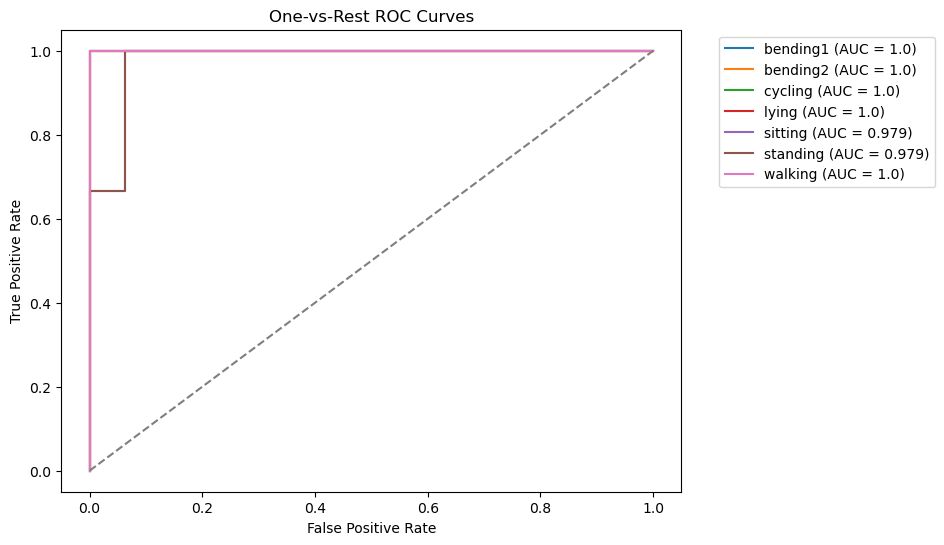

In [51]:
y_test_multi_prob = multi_model.predict_proba(
    X_test_multi
)

y_test_multi_bin = label_binarize(
    y_test_multi,
    classes=class_names
)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(
    class_names
):
    
    fpr, tpr, thresholds = roc_curve(
        y_test_multi_bin[:, i],
        y_test_multi_prob[:, i]
    )
    
    class_auc = auc(
        fpr,
        tpr
    )
    
    plt.plot(
        fpr,
        tpr,
        label=(
            class_name +
            ' (AUC = ' +
            str(round(class_auc, 3)) +
            ')'
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel(
    'False Positive Rate'
)

plt.ylabel(
    'True Positive Rate'
)

plt.title(
    'One-vs-Rest ROC Curves'
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.show()

In [52]:
macro_auc = roc_auc_score(
    y_test_multi_bin,
    y_test_multi_prob,
    average='macro'
)

print(
    "Macro-average AUC:",
    round(
        macro_auc,
        4
    )
)

Macro-average AUC: 0.994


The best L1-penalized multinomial logistic regression model was obtained with $l=1$ and $C=43.9397$. The cross-validation accuracy is 0.8987.

The test accuracy is 0.8947, corresponding to a test error of

$$
1 - 0.8947 = 0.1053.
$$

From the confusion matrix, most of the activity classes are classified correctly. There are two misclassified test instances: one sitting instance is classified as standing, and one standing instance is classified as lying.

For the multiclass ROC analysis, I used the one-vs-rest approach. The macro-average AUC is 0.994, indicating that the model has strong overall ability to distinguish among the seven activity classes.

Since the smallest class in the training set contains only 4 observations, I used 4-fold stratified cross-validation instead of 5-fold cross-validation so that every fold could contain observations from each activity class.

## 2(c)(ii)

In [53]:
nb_results = []

for l in range(1, 21):
    
    X, y = make_multiclass_features(
        train_files,
        l
    )
    
    gaussian_model = GaussianNB()
    
    gaussian_scores = cross_val_score(
        gaussian_model,
        X,
        y,
        cv=cv_multi,
        scoring='accuracy'
    )
    
    multinomial_model = MultinomialNB()
    
    multinomial_scores = cross_val_score(
        multinomial_model,
        X,
        y,
        cv=cv_multi,
        scoring='accuracy'
    )
    
    nb_results.append({
        'l': l,
        'Gaussian CV Accuracy': gaussian_scores.mean(),
        'Multinomial CV Accuracy': multinomial_scores.mean()
    })

In [54]:
nb_results_df = pd.DataFrame(
    nb_results
)

nb_results_df

,l,Gaussian CV Accuracy,Multinomial CV Accuracy
0,1,0.884804,0.869281
1,2,0.855392,0.869281
2,3,0.825980,0.869281
3,4,0.883987,0.868464
4,5,0.825163,0.853758
5,6,0.839869,0.825163
6,7,0.825163,0.853758
7,8,0.752451,0.840686
8,9,0.781863,0.854575
9,10,0.795752,0.811275


In [55]:
best_gaussian_row = nb_results_df.loc[
    nb_results_df[
        'Gaussian CV Accuracy'
    ].idxmax()
]

best_multinomial_row = nb_results_df.loc[
    nb_results_df[
        'Multinomial CV Accuracy'
    ].idxmax()
]

best_gaussian_l = int(
    best_gaussian_row['l']
)

best_multinomial_l = int(
    best_multinomial_row['l']
)

best_gaussian_cv = best_gaussian_row[
    'Gaussian CV Accuracy'
]

best_multinomial_cv = best_multinomial_row[
    'Multinomial CV Accuracy'
]

print(
    "GaussianNB best l:",
    best_gaussian_l
)

print(
    "GaussianNB CV accuracy:",
    round(best_gaussian_cv, 4)
)

print(
    "MultinomialNB best l:",
    best_multinomial_l
)

print(
    "MultinomialNB CV accuracy:",
    round(best_multinomial_cv, 4)
)

GaussianNB best l: 1
GaussianNB CV accuracy: 0.8848
MultinomialNB best l: 1
MultinomialNB CV accuracy: 0.8693


In [56]:
X_train_gaussian, y_train_gaussian = (
    make_multiclass_features(
        train_files,
        best_gaussian_l
    )
)

X_test_gaussian, y_test_gaussian = (
    make_multiclass_features(
        test_files,
        best_gaussian_l
    )
)

gaussian_model = GaussianNB()

gaussian_model.fit(
    X_train_gaussian,
    y_train_gaussian
)

gaussian_pred = gaussian_model.predict(
    X_test_gaussian
)

gaussian_prob = gaussian_model.predict_proba(
    X_test_gaussian
)

gaussian_accuracy = accuracy_score(
    y_test_gaussian,
    gaussian_pred
)

gaussian_error = 1 - gaussian_accuracy

print(
    "GaussianNB test accuracy:",
    round(gaussian_accuracy, 4)
)

print(
    "GaussianNB test error:",
    round(gaussian_error, 4)
)

GaussianNB test accuracy: 0.8947
GaussianNB test error: 0.1053


In [57]:
X_train_multinomial, y_train_multinomial = (
    make_multiclass_features(
        train_files,
        best_multinomial_l
    )
)

X_test_multinomial, y_test_multinomial = (
    make_multiclass_features(
        test_files,
        best_multinomial_l
    )
)

print(
    "Minimum feature value:",
    X_train_multinomial.min().min()
)

Minimum feature value: 0.007166666666666667


In [58]:
multinomial_model = MultinomialNB()

multinomial_model.fit(
    X_train_multinomial,
    y_train_multinomial
)

multinomial_pred = multinomial_model.predict(
    X_test_multinomial
)

multinomial_prob = multinomial_model.predict_proba(
    X_test_multinomial
)

multinomial_accuracy = accuracy_score(
    y_test_multinomial,
    multinomial_pred
)

multinomial_error = 1 - multinomial_accuracy

print(
    "MultinomialNB test accuracy:",
    round(multinomial_accuracy, 4)
)

print(
    "MultinomialNB test error:",
    round(multinomial_error, 4)
)

MultinomialNB test accuracy: 0.8947
MultinomialNB test error: 0.1053


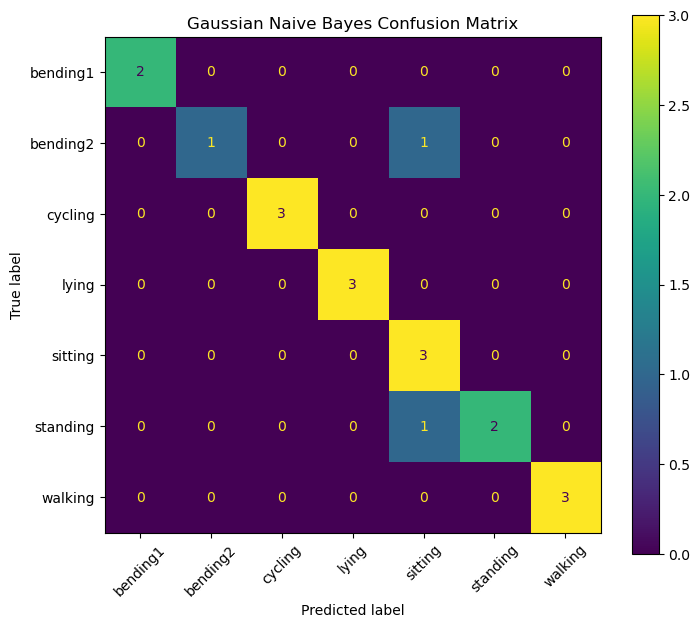

In [59]:
gaussian_cm = confusion_matrix(
    y_test_gaussian,
    gaussian_pred,
    labels=activities
)

display = ConfusionMatrixDisplay(
    confusion_matrix=gaussian_cm,
    display_labels=activities
)

fig, ax = plt.subplots(
    figsize=(8, 7)
)

display.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    'Gaussian Naive Bayes Confusion Matrix'
)

plt.show()

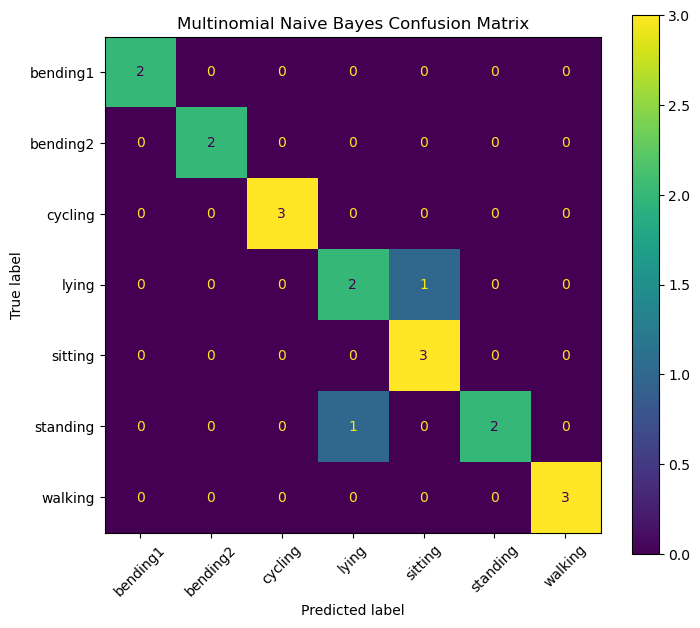

In [60]:
multinomial_cm = confusion_matrix(
    y_test_multinomial,
    multinomial_pred,
    labels=activities
)

display = ConfusionMatrixDisplay(
    confusion_matrix=multinomial_cm,
    display_labels=activities
)

fig, ax = plt.subplots(
    figsize=(8, 7)
)

display.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    'Multinomial Naive Bayes Confusion Matrix'
)

plt.show()

In [61]:
gaussian_classes = gaussian_model.classes_

y_test_gaussian_bin = label_binarize(
    y_test_gaussian,
    classes=gaussian_classes
)

gaussian_auc = roc_auc_score(
    y_test_gaussian_bin,
    gaussian_prob,
    average='macro',
    multi_class='ovr'
)

multinomial_classes = multinomial_model.classes_

y_test_multinomial_bin = label_binarize(
    y_test_multinomial,
    classes=multinomial_classes
)

multinomial_auc = roc_auc_score(
    y_test_multinomial_bin,
    multinomial_prob,
    average='macro',
    multi_class='ovr'
)

print(
    "GaussianNB macro AUC:",
    round(gaussian_auc, 4)
)

print(
    "MultinomialNB macro AUC:",
    round(multinomial_auc, 4)
)

GaussianNB macro AUC: 0.997
MultinomialNB macro AUC: 0.9881


The best value of $l$ is 1 for both Gaussian Naive Bayes and Multinomial Naive Bayes.

Gaussian Naive Bayes has a cross-validation accuracy of 0.8848, while Multinomial Naive Bayes has a cross-validation accuracy of 0.8693.

On the test set, both models achieve the same accuracy of 0.8947, corresponding to a test error of 0.1053.

The macro-average AUC is 0.9970 for Gaussian Naive Bayes and 0.9881 for Multinomial Naive Bayes. Therefore, Gaussian Naive Bayes performs slightly better overall because it has higher cross-validation accuracy and a higher AUC, even though both models have the same test accuracy.

## 2(c)(iii)

Among the three methods, the L1-penalized multinomial logistic regression performs the best overall.

The multinomial logistic regression has a cross-validation accuracy of 0.8987 and a test accuracy of 0.8947, with a macro-average AUC of 0.9940.

Gaussian Naive Bayes has a slightly lower cross-validation accuracy of 0.8848, the same test accuracy of 0.8947, and a slightly higher macro-average AUC of 0.9970.

Multinomial Naive Bayes has the lowest cross-validation accuracy of 0.8693, the same test accuracy of 0.8947, and a macro-average AUC of 0.9881.

Overall, I would choose the L1-penalized multinomial logistic regression because it has the highest cross-validation accuracy and the same test accuracy as the Naive Bayes models. Gaussian Naive Bayes is also competitive, especially based on its AUC.

## 3

For class $k$, we have

$$
X \sim N(\mu_k,\sigma_k^2).
$$

The density function is

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Using Bayes' rule, we assign an observation to the class that gives the largest value of

$$
\pi_k f_k(x),
$$

where $\pi_k$ is the prior probability of class $k$.

Taking the log, we get

$$
\delta_k(x)
=
\log(\pi_k)
-
\log(\sigma_k)
-
\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-
\log(\sigma_k)
+
\log(\pi_k).
$$

The important part is that this expression contains an $x^2$ term. Its coefficient depends on $\sigma_k^2$, so if different classes have different variances, the quadratic terms do not cancel.

For two classes, the decision boundary is found by setting

$$
\delta_k(x)=\delta_l(x).
$$

This results in an equation that contains an $x^2$ term, so the boundary is quadratic instead of linear.

Therefore, when the classes have different variances, the Bayes classifier is quadratic. If all classes had the same variance, the $x^2$ terms would cancel and the classifier would become linear.

## 4

Let $Y$ mean the company issues a dividend and $N$ mean it does not.

From the problem,

$$
P(Y)=0.8
$$

and

$$
P(N)=0.2.
$$

Also,

$$
\mu_Y=10,\quad \mu_N=0,\quad \sigma^2=36.
$$

We want to find

$$
P(Y\mid X=4).
$$

Using Bayes' theorem,

$$
P(Y\mid X=4)
=
\frac{P(Y)f_Y(4)}
{P(Y)f_Y(4)+P(N)f_N(4)}.
$$

Since both classes have the same variance, the normal density constants cancel. So,

$$
P(Y\mid X=4)
=
\frac{
0.8e^{-\frac{(4-10)^2}{72}}
}{
0.8e^{-\frac{(4-10)^2}{72}}
+
0.2e^{-\frac{(4-0)^2}{72}}
}.
$$

Now,

$$
\frac{(4-10)^2}{72}
=
\frac{36}{72}
=
0.5
$$

and

$$
\frac{(4-0)^2}{72}
=
\frac{16}{72}
\approx 0.2222.
$$

Therefore,

$$
P(Y\mid X=4)
=
\frac{
0.8e^{-0.5}
}{
0.8e^{-0.5}
+
0.2e^{-0.2222}
}
\approx 0.752.
$$

So the probability that the company will issue a dividend is about

$$
75.2\%.
$$